In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("seeds/seeds_dataset.txt", sep=r"\s+", header=None)

df.columns = [
    "area", "perimeter", "compactness",
    "kernel_length", "kernel_width",
    "asymmetry_coefficient", "groove_length",
    "class"
]

In [3]:
print(df.head(5))

    area  perimeter  compactness  kernel_length  kernel_width  \
0  15.26      14.84       0.8710          5.763         3.312   
1  14.88      14.57       0.8811          5.554         3.333   
2  14.29      14.09       0.9050          5.291         3.337   
3  13.84      13.94       0.8955          5.324         3.379   
4  16.14      14.99       0.9034          5.658         3.562   

   asymmetry_coefficient  groove_length  class  
0                  2.221          5.220      1  
1                  1.018          4.956      1  
2                  2.699          4.825      1  
3                  2.259          4.805      1  
4                  1.355          5.175      1  


A1: chuẩn hóa từng đặc trưng về mean 0 std 1

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df),
    columns=df.columns
)

In [5]:
print(df_scaled.head(5))

       area  perimeter  compactness  kernel_length  kernel_width  \
0  0.142098   0.215462     0.000061       0.304218      0.141702   
1  0.011188   0.008224     0.428515      -0.168625      0.197432   
2 -0.192067  -0.360201     1.442383      -0.763637      0.208048   
3 -0.347091  -0.475333     1.039381      -0.688978      0.319508   
4  0.445257   0.330595     1.374509       0.066666      0.805159   

   asymmetry_coefficient  groove_length     class  
0              -0.986152      -0.383577 -1.224745  
1              -1.788166      -0.922013 -1.224745  
2              -0.667479      -1.189192 -1.224745  
3              -0.960818      -1.229983 -1.224745  
4              -1.563495      -0.475356 -1.224745  


A2: Tính tích vô hướng euclid của 5 mẫu đầu tiên

In [14]:
X = df_scaled.iloc[:5].to_numpy()
dot_product = X @ X.T

df_dot = pd.DataFrame(dot_product, index=range(1, 6), columns=range(1, 6))
print(df_dot)
# print(dot_product)

          1         2         3         4         5
1  2.798871  3.597132  2.306737  2.603307  3.493137
2  3.597132  5.798879  4.572831  4.969021  5.478496
3  2.306737  4.572831  6.233236  5.933680  5.003463
4  2.603307  4.969021  5.933680  5.939532  4.915190
5  3.493137  5.478496  5.003463  4.915190  7.020030


A3: tính tích vô hướng có trọng số của 5 mẫu đầu tiên

In [15]:
A = np.diag(np.array([0.25, 0.25, 1, 0.25, 0.25, 1, 1, 2]))
dot_product2 = X @ A @ X.T

df_dot2 = pd.DataFrame(dot_product2, index=range(1, 6), columns=range(1, 6))
print(df_dot2)


          1         2         3         4         5
1  4.164438  5.112103  4.037537  4.340353  4.791482
2  5.112103  7.248174  5.949281  6.340420  6.861929
3  4.037537  5.949281  7.138441  6.810818  6.569461
4  4.340353  6.340420  6.810818  6.747139  6.490463
5  4.791482  6.861929  6.569461  6.490463  7.799825


A4: so sánh mẫu gần nhau nhất ở hai tích vô hướng

In [13]:
print('Dot product without weighted matrix')
for i in range(5):
    print(f'{i+1} is nearest to {[j+1 for j in range(len(dot_product[i])) if dot_product[i][j] == min(dot_product[i])]}: {min(dot_product[i])}')

Dot product without weighted matrix
1 is nearest to [3]: 2.306736901038405
2 is nearest to [1]: 3.597132265107032
3 is nearest to [1]: 2.306736901038405
4 is nearest to [1]: 2.6033067629991877
5 is nearest to [1]: 3.4931372865559562


In [12]:
print('Dot product with weighted matrix')
for i in range(5):
    print(f'{i+1} is nearest to {[j+1 for j in range(len(dot_product2[i])) if dot_product2[i][j] == min(dot_product2[i])]}: {min(dot_product2[i])}')

Dot product with weighted matrix
1 is nearest to [3]: 4.037537114168054
2 is nearest to [1]: 5.112102625519909
3 is nearest to [1]: 4.037537114168054
4 is nearest to [1]: 4.340353325442398
5 is nearest to [1]: 4.7914816030421195


Phần phụ tự làm không có trong đề(để xem thôi): PCA 7 chiều còn 2 chiều cho 210 hạt thuộc 3 nhóm

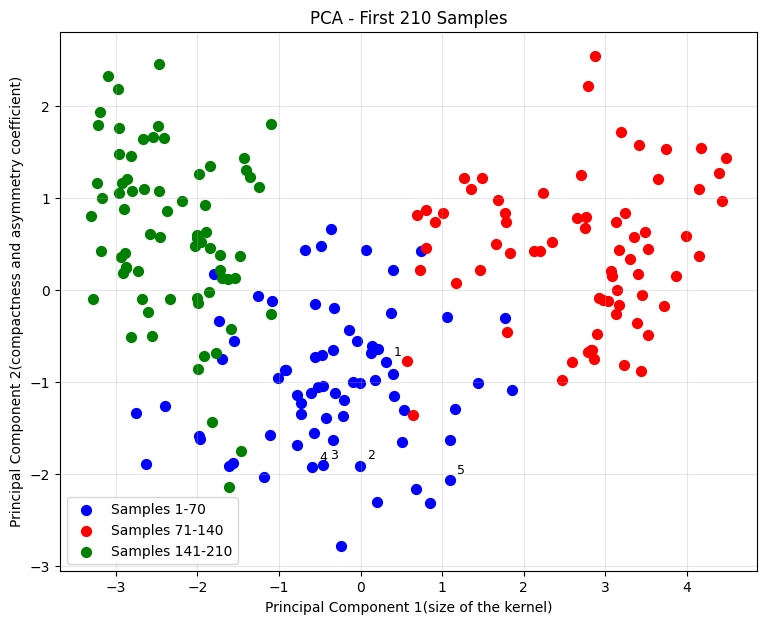

Explained variance ratio: [0.71874303 0.17108184]
Total explained variance: 0.8898248618491231


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Lấy 210 dòng đầu tiên
X = df_scaled.drop(columns=["class"]).iloc[:210].to_numpy()

# 2. PCA giảm xuống 2 chiều
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

# 3. Chia thành 3 nhóm
group1 = X_2d[:70]      # Dòng 1-70
group2 = X_2d[70:140]   # Dòng 71-140
group3 = X_2d[140:210]  # Dòng 141-210

# 4. Plot
plt.figure(figsize=(9, 7))

plt.scatter(group1[:, 0], group1[:, 1],
            color="blue", label="Samples 1-70", s=50)

plt.scatter(group2[:, 0], group2[:, 1],
            color="red", label="Samples 71-140", s=50)

plt.scatter(group3[:, 0], group3[:, 1],
            color="green", label="Samples 141-210", s=50)
# Gắn tên cho 5 điểm đầu tiên
for i in range(5):
    plt.annotate(
        f"{i+1}",
        (X_2d[i, 0], X_2d[i, 1]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Principal Component 1(size of the kernel)")
plt.ylabel("Principal Component 2(compactness and asymmetry coefficient)")
plt.title("PCA - First 210 Samples")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 5. Explained variance
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", sum(pca.explained_variance_ratio_))

In [22]:
# Chỉ lấy 7 đặc trưng, loại bỏ class
X = df_scaled.drop(columns=["class"]).iloc[:210].to_numpy()

# PCA
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

# Loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=df_scaled.drop(columns=["class"]).columns,
    columns=["PC1", "PC2"]
)

print(loadings)

                            PC1       PC2
area                   0.444474  0.026564
perimeter              0.441571  0.084003
compactness            0.277017 -0.529151
kernel_length          0.423563  0.205975
kernel_width           0.432819 -0.116690
asymmetry_coefficient -0.118692  0.716882
groove_length          0.387161  0.377193
